In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""End-to-end, GUI-free FROG workflow with croak.

Synthesises an experimental-style FROG file, then runs the full library
pipeline: load → clean/regrid → retrieve → post-process → plot → save. Run::

    uv run python examples/example_workflow.py

Writes ``retrieval.png`` and ``retrieval.h5`` to the working directory and
prints the FROG error and recovered/transform-limited pulse widths.
"""

from __future__ import annotations

import tempfile
from pathlib import Path

import h5py
import matplotlib
import numpy as np

matplotlib.use("Agg")

import croak
from croak.maths import wlfreq
from croak.preprocess import omega_to_lambda_density


def make_experiment_file(path: str) -> tuple[float, float]:
    """Write a synthetic PG-FROG file (wavelength/delay/trace); return (λmin, λmax)."""
    # The time window (n*dt = 102 fs) must comfortably exceed the delay range plus
    # the pulse extent. If it does not, the gated signal wraps around the periodic
    # FFT window and the synthesised "measurement" carries a spurious second copy
    # of the pulse — which no retrieval can then fit.
    g = croak.Grid(256, dt=0.4e-15)
    omega0 = wlfreq(800e-9)
    ew = croak.gaussian_pulse(g, 6e-15, phases=[25e-30])  # chirped, ~13 fs
    delays = np.linspace(-40e-15, 40e-15, 90)
    trace = croak.maketrace(g.omega, delays, ew, "pg")

    omega_abs = g.omega + omega0
    band = (omega_abs > 0.45 * omega0) & (omega_abs < 2.0 * omega0)
    lam = wlfreq(omega_abs[band])
    order = np.argsort(lam)
    lam_nm = lam[order] / 1e-9
    # maketrace returns a *frequency* density I_w; a spectrometer records a
    # *wavelength* density I_l = I_w |dw/dl|. load_and_clean expects the latter
    # and multiplies by lambda^2 to undo it, so convert here or the Jacobian is
    # applied twice.
    trace_exp = omega_to_lambda_density(trace[band][order, :], lam[order])
    trace_exp = trace_exp / trace_exp.max()  # detector counts: arbitrary units

    with h5py.File(path, "w") as f:
        f["wavelength"] = lam_nm
        f["delay"] = delays / 1e-15
        f["trace"] = trace_exp

    # Band from the wavelength marginal at 1e-4 of its peak (the -40 dB point,
    # where the signal really ends on a log plot). A few-percent cut looks
    # generous on a linear scale but can clip informative wings. This noise-free
    # threshold is illustrative; measured data needs a noise-floor check.
    marg = trace_exp.sum(axis=1)
    sig = np.where(marg > 1e-4 * marg.max())[0]
    return lam_nm[sig[0]] * 1e-9, lam_nm[sig[-1]] * 1e-9


def main() -> None:
    workspace = tempfile.TemporaryDirectory(prefix="croak-example-")
    tmp = Path(workspace.name)
    h5_path = str(tmp / "croak_experiment.h5")
    lam_min, lam_max = make_experiment_file(h5_path)

    # --- load datasets (as the GUI would, via the generic picker) ---
    fd = croak.io.list_datasets(h5_path)
    lam = fd.load("wavelength") * croak.io.unit_to_si("nm")
    delays = fd.load("delay") * croak.io.unit_to_si("fs")
    trace = fd.load("trace")

    # --- clean & regrid ---
    td = croak.load_and_clean(
        trace,
        lam,
        delays,
        "pg",
        lam_min=lam_min,
        lam_max=lam_max,
        input_unit="delay",
        # Every filter (fringe notch, DC removal, delay low-pass, baseline,
        # threshold) is off by default: each removes real signal along with its
        # target. Only `prefilter`, the anti-alias low-pass that resampling
        # requires, runs here.
    )
    print(f"Regridded trace: {td.trace.shape[0]} freqs × {td.delays.size} delays")

    # --- retrieve ---
    result = croak.retrieve_from_tracedata(
        td, algorithm="copra", maxiters=250, rng=np.random.default_rng(0)
    )
    print(f"FROG error R = {result.error:.4%}")

    # --- post-process ---
    pr = croak.process_result(result, measured=td.trace)
    print(
        f"Recovered FWHM = {pr.fwhm_retr / 1e-15:.2f} fs "
        f"(transform-limited {pr.fwhm_tl / 1e-15:.2f} fs)"
    )
    print(f"Fitted GDD = {pr.gdd_fs2:.0f} fs²,  TOD = {pr.tod_fs3:.0f} fs³")
    # Sanity check on the spectrum itself: energy in the unmeasured grid-edge bins.
    # Low edge energy is useful but does not prove the field is correct;
    # inspect the band, phase and residual as well.
    print(f"Edge energy = {pr.edge_energy:.3%} (taper loss {td.taper_loss:.3%})")

    # --- plot & save ---
    fig = croak.plot_retrieval(
        result,
        measured=td.trace,
        Iomega_meas=td.Iomega,
        lam_min=td.lam_min,
        lam_max=td.lam_max,
    )
    fig.savefig("retrieval.png", dpi=110)
    croak.save_result(result, "retrieval.h5", processed=pr, force=True)
    print("Wrote retrieval.png and retrieval.h5")


if __name__ == "__main__":
    main()


Regridded trace: 54 freqs × 90 delays


FROG error R = 0.0298%
Recovered FWHM = 13.02 fs (transform-limited 6.08 fs)
Fitted GDD = 25 fs²,  TOD = 0 fs³
Edge energy = 0.160% (taper loss 0.139%)


Wrote retrieval.png and retrieval.h5


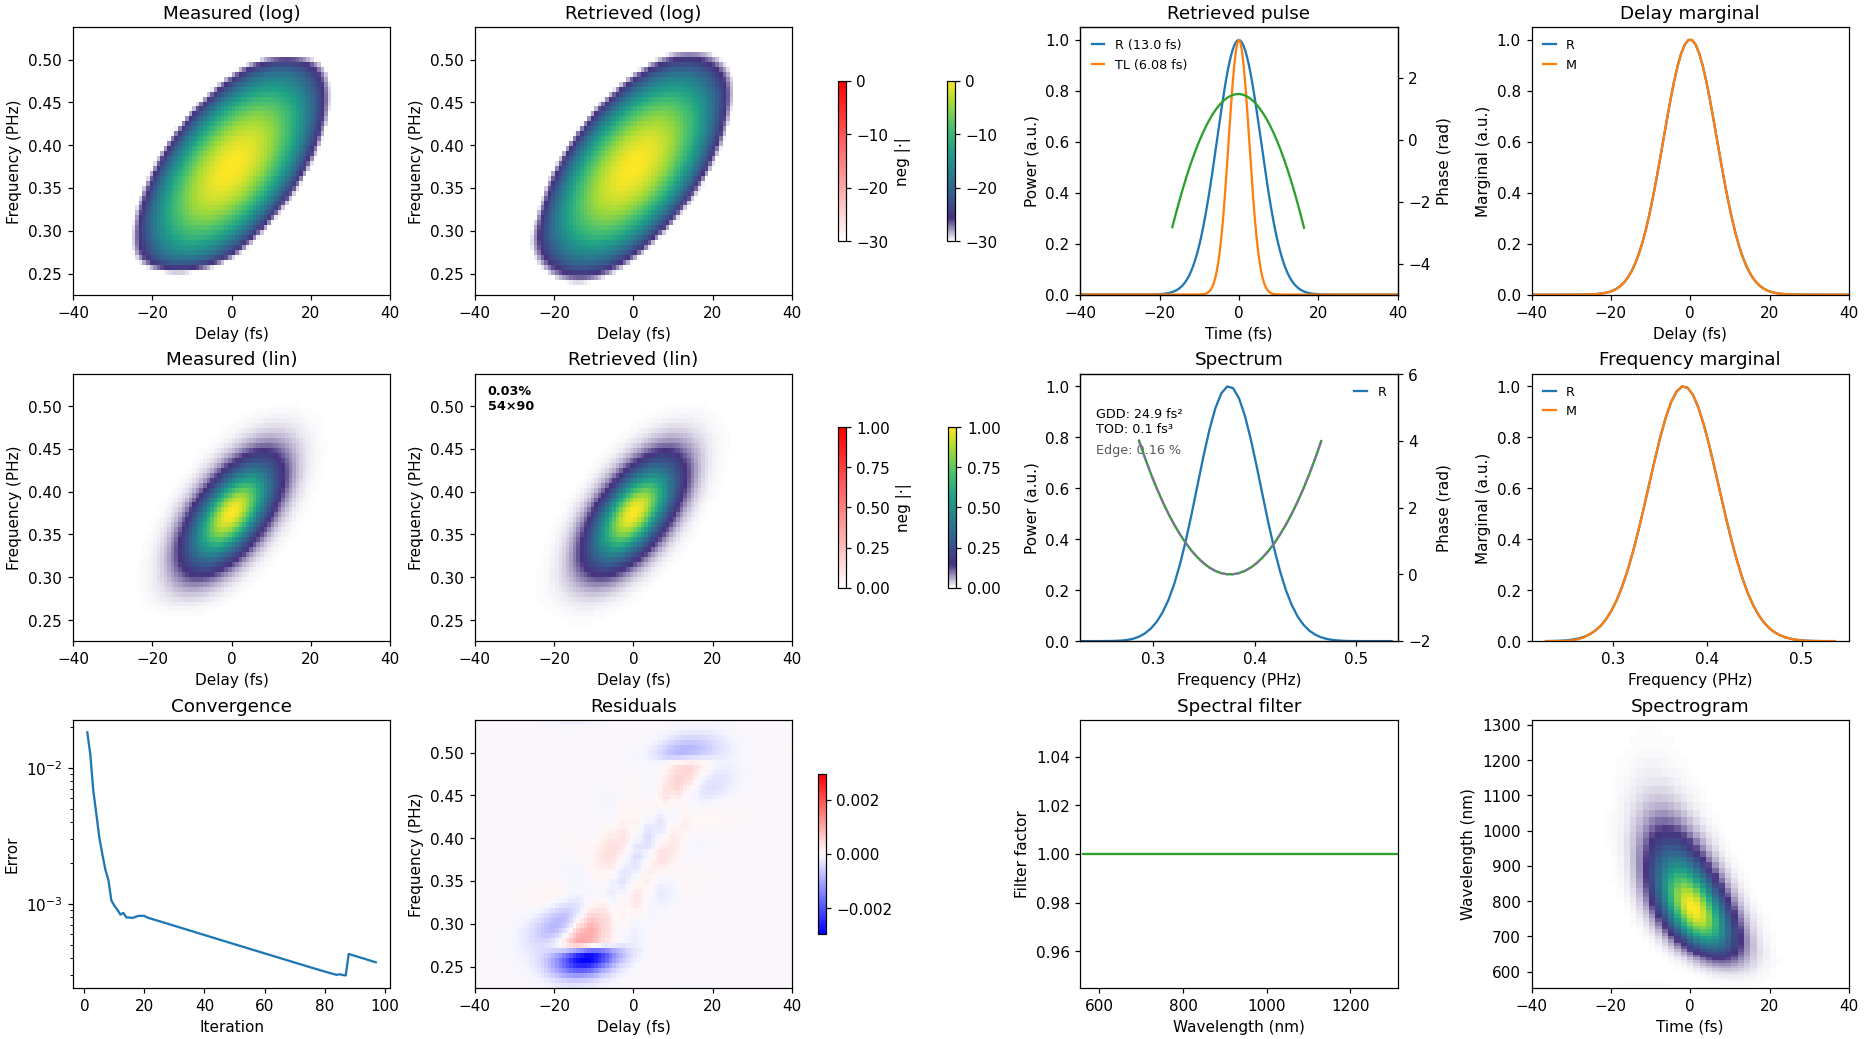

In [3]:
display(Image(filename="retrieval.png"))